In [1]:
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

import gmsh

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.FluidFlow import ff
from Source.Physics.Viscoelastic import ve
from Source.enums import StudyType, ProblemType

In [2]:
H, h, L1, L2 = 4.0, 1.0, 20.0, 20.0
U = 1.0
MU, BETA = 1.0, 1.0 / 9.0
DIVISIONS = 4
DE_MAX = 1.5
ALPHA = 0.0
STEP = 0.1

In [3]:
def contraction_mesh(lc, refine=0.15):

    """Triangulos cuadraticos con la malla refinada en la esquina reentrante (0, h) y una zona fina alrededor de ella."""

    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    try:
        geo = gmsh.model.geo
        far = 4.0 * lc
        points = [(-L1, 0, far), (L2, 0, far), (L2, h, far), (0, h, lc * refine), (0, H, lc), (-L1, H, far)]
        tags = [geo.addPoint(x, y, 0, size) for x, y, size in points]
        lines = [geo.addLine(tags[i], tags[(i + 1) % 6]) for i in range(6)]
        geo.addPlaneSurface([geo.addCurveLoop(lines)])
        geo.synchronize()
        for name, group in (('axis', lines[:1]), ('outlet', lines[1:2]), ('walls', lines[2:5]), ('inlet', lines[5:])):
            gmsh.model.addPhysicalGroup(1, group, name=name)
        gmsh.model.mesh.generate(2)
        gmsh.model.mesh.setOrder(2)
        return Mesh.from_gmsh_model()
    finally:
        gmsh.finalize()

In [4]:
lc_wall = h / DIVISIONS
mesh = contraction_mesh(lc_wall)
xy = np.array([n.coor for n in mesh.NL])
mu_s, mu_p = BETA * MU, (1 - BETA) * MU

In [5]:
de = 0.25
model = Model(name='contraccion', dim=2, mesh=mesh, mat=material('X', miu=mu_s), psc=[ff, ve])
flow, polymer = model.physics.fluid, model.physics.viscoelastic
polymer.setModes([(mu_p, de * h / U, ALPHA)])
polymer.setDEVSS(mu_p)

inlet, outlet = mesh.boundary_edges('inlet'), mesh.boundary_edges('outlet')
U_in = 1.5 * U * h / H                                       # velocidad maxima de la parabola de entrada: mismo caudal
flow.addBC_VelocityEdges(inlet, lambda x, y: (U_in * (1 - (y / H) ** 2), 0.0))
flow.addBC_NoSlipEdges(mesh.boundary_edges('walls'))
flow.addBC_SymmetryEdges(mesh.boundary_edges('axis'))
flow.addBC_OutletEdges(outlet, 0.0)
polymer.addBC_OutletEdges(outlet)
polymer.addBC_InflowEdges(inlet, lambda x, y: [[0.0, -2.0 * U_in * y / H ** 2], [0.0, 0.0]])
print(f"Malla: {mesh.getNoN()} nodos, {model.layout.ndof} incognitas; beta = {BETA:.3f}, alpha = {ALPHA}")

Malla: 1723 nodos, 17230 incognitas; beta = 0.111, alpha = 0.0


In [6]:
model.solverConfiguration(Study=StudyType.steady_state, Type=ProblemType.nonlinear)
model.solve()

2026-11-02 14:10:04 - INFO - ------- Starting simulation -------
2026-11-02 14:10:04 - INFO - Model: contraccion
2026-11-02 14:10:04 - INFO - Dimension: 2D
2026-11-02 14:10:04 - INFO - Nodes: 1723
2026-11-02 14:10:04 - INFO - Elements: 772
2026-11-02 14:10:04 - INFO - Physics: Creeping flow (Stokes) + Viscoelastic polymer modes
2026-11-02 14:10:04 - INFO - ------- Solver configuration -------
2026-11-02 14:10:04 - INFO - Study: Steady state
2026-11-02 14:10:04 - INFO - Type: Nonlinear
2026-11-02 14:10:04 - INFO - Method: Direct
2026-11-02 14:10:04 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-11-02 14:10:04 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-11-02 14:10:04 - INFO - Relative tolerance: 1.0e-10, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-11-02 14:10:04 - INFO - -----------------------------------------------------------
2026-11-02 14:10:04 - INFO - |  Iter  |  ||R|| scaled   |  ||R||/||R0||   | Alpha (Step)
2026-11-

In [7]:
model.sol.keys()

dict_keys(['u', 'p', 'b0', 'G', 'shear_rate', 'polymer_stress'])

In [8]:
model.sol['polymer_stress'][10]

array([-1.09027657e-04, -7.75301430e-07,  1.71926362e-05])

In [9]:
xy

array([[-20.        ,   0.        ],
       [ 20.        ,   0.        ],
       [ 20.        ,   1.        ],
       ...,
       [  0.14631047,   0.86844943],
       [  2.70639931,   0.67164835],
       [  1.12895354,   0.8531991 ]], shape=(1723, 2))

In [10]:
mesh.EL[0].getNodesId()

[384, 145, 385, 654, 655, 656]

In [11]:
# Mesh.triangulation divide cada T6 en 4 triangulos de 3 nodos (usa todos los nodos), que es lo que pide matplotlib
triang = mesh.triangulation()

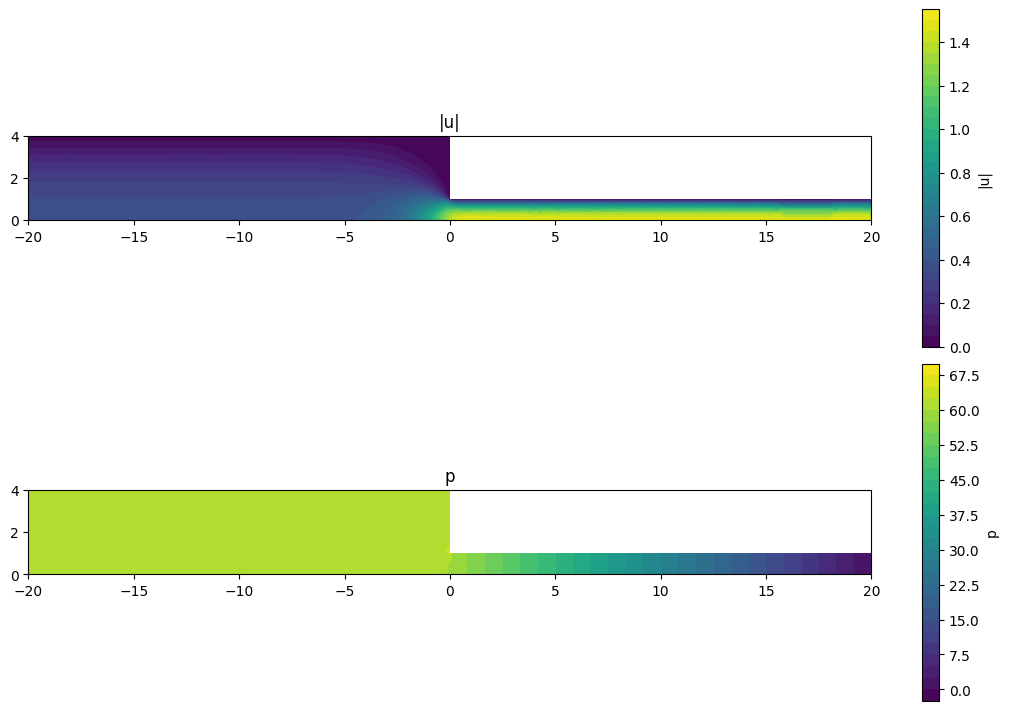

In [12]:
u = np.asarray(model.sol['u']).reshape(len(xy), -1)
speed = np.hypot(u[:, 0], u[:, 1])
p = np.asarray(model.sol['p']).ravel()

fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
for ax, field, title in ((axes[0], speed, '|u|'), (axes[1], p, 'p')):
    c = ax.tricontourf(triang, field, levels=30, cmap='viridis')
    fig.colorbar(c, ax=ax, label=title)
    ax.set_aspect('equal'); ax.set_title(title)
plt.show()

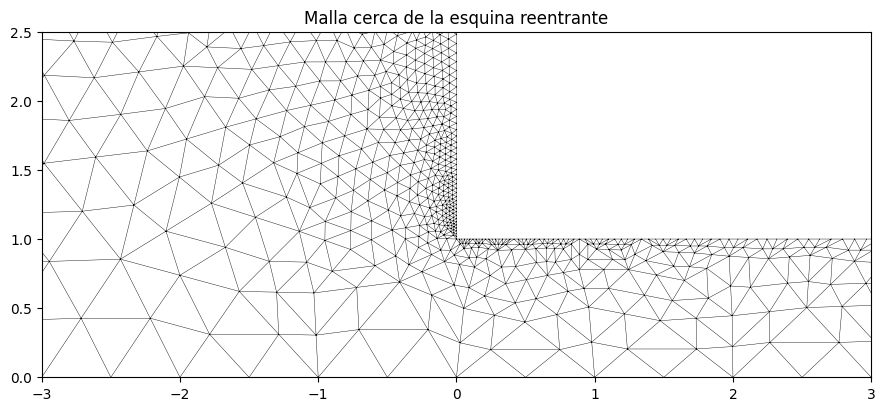

In [13]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.triplot(triang, lw=0.3, color='k')
ax.set_xlim(-3, 3); ax.set_ylim(0, 2.5); ax.set_aspect('equal'); ax.set_title('Malla cerca de la esquina reentrante')
plt.show()

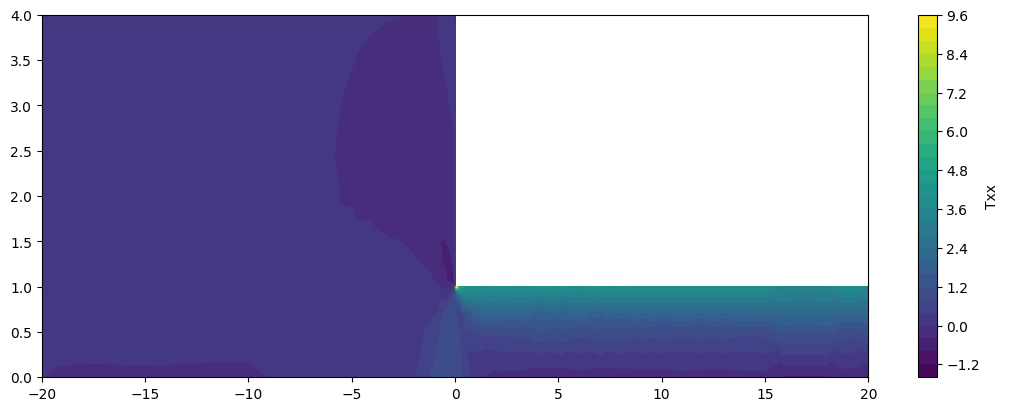

In [14]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
c = ax.tricontourf(triang, np.asarray(model.sol['polymer_stress'][:, 0]).ravel(), levels=30, cmap='viridis')
fig.colorbar(c, ax=ax, label='Txx') 

In [15]:
def tanner_swell():

    """Estimacion de Tanner en la pared del tramo desarrollado, flujo plano: (1 + (N1 / (2 tau_w))^2 / 2)^(1/4)."""

    section = (np.abs(xy[:, 0] - 0.5 * L2) < 1.5 * h) & (xy[:, 1] > h - 1e-9)
    s = model.sol['polymer_stress'][section].mean(axis=0)
    return (1.0 + 0.5 * ((s[0] - s[2]) / (2.0 * (s[1] + mu_s * -3.0 * U / h))) ** 2) ** (1.0 / 4.0)

In [16]:
tanner_swell()

np.float64(1.0493779893379223)

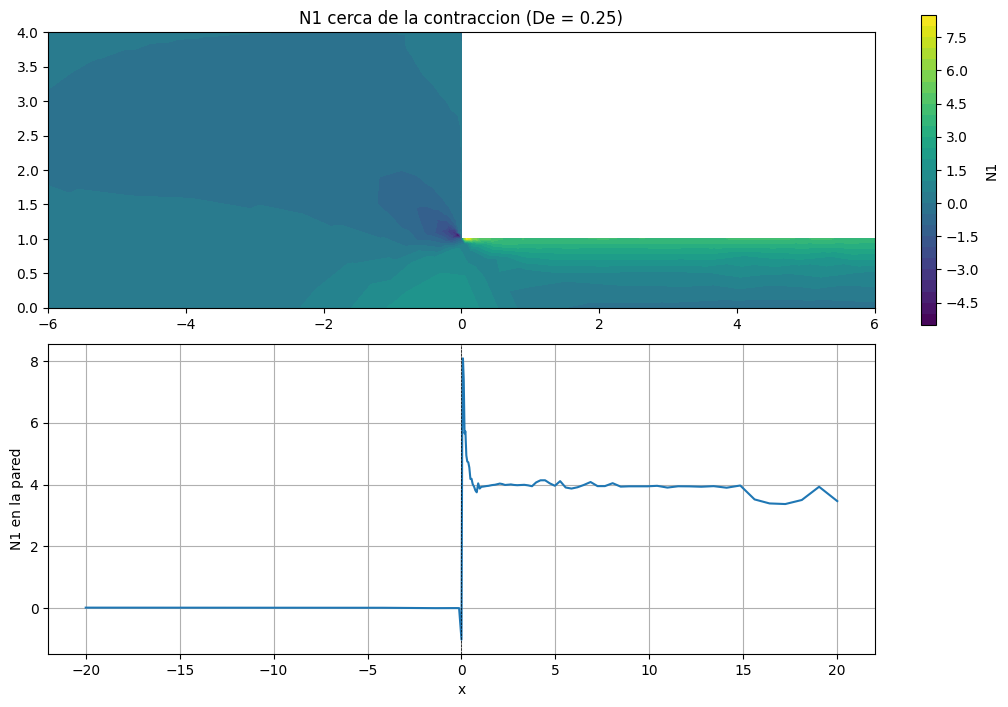

In [17]:
# Primera diferencia de esfuerzos normales N1 = tau_xx - tau_yy (solo el polimero: el solvente newtoniano no aporta)
tau = np.asarray(model.sol['polymer_stress'])
N1 = tau[:, 0] - tau[:, 2]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)

c = axes[0].tricontourf(triang, N1, levels=30, cmap='viridis')
fig.colorbar(c, ax=axes[0], label='N1')
axes[0].set_xlim(-6, 6); axes[0].set_ylim(0, H); axes[0].set_aspect('equal')
axes[0].set_title(f'N1 cerca de la contraccion (De = {de:.2f})')

# a lo largo de la pared superior (y = H aguas arriba, y = h aguas abajo), ordenada por x
wall = np.where(np.isclose(xy[:, 1], np.where(xy[:, 0] < 0, H, h)))[0]
wall = wall[np.argsort(xy[wall, 0])]
axes[1].plot(xy[wall, 0], N1[wall], '-')
axes[1].axvline(0.0, color='k', lw=0.5, ls='--')
axes[1].set_xlabel('x'); axes[1].set_ylabel('N1 en la pared'); axes[1].grid(True)
plt.show()

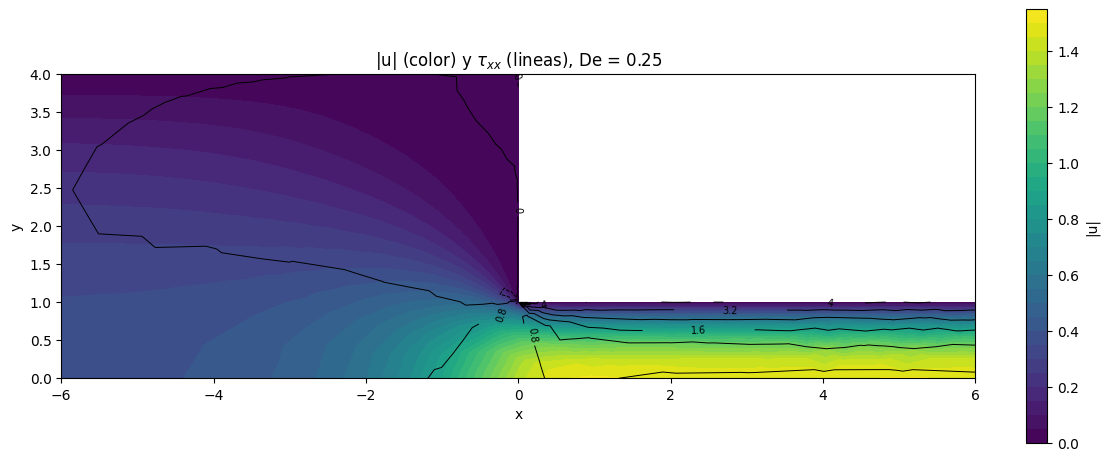

In [18]:
# Magnitud de la velocidad en color y lineas de nivel de tau_xx (esfuerzo polimerico)
u = np.asarray(model.sol['u']).reshape(len(xy), -1)
speed = np.hypot(u[:, 0], u[:, 1])
txx = np.asarray(model.sol['polymer_stress'])[:, 0]

fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
fill = ax.tricontourf(triang, speed, levels=30, cmap='viridis')
fig.colorbar(fill, ax=ax, label='|u|')
lines = ax.tricontour(triang, txx, levels=15, colors='k', linewidths=0.7)
ax.clabel(lines, fontsize=7, fmt='%.2g')
ax.set_xlim(-6, 6); ax.set_ylim(0, H); ax.set_aspect('equal')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title(rf'|u| (color) y $\tau_{{xx}}$ (lineas), De = {de:.2f}')
plt.show()